## Exploring High Dimensional Data

In [7]:
# Load pokemon data
import pandas as pd
pokemon_df = pd.read_csv('data/pokemon.csv', index_col=0)

# Get first 160 rows of the dataset
pokemon_sample = pokemon_df.iloc[:160, :]

print(pokemon_sample.head())

                    Name Type 1  Type 2  Total  HP  Attack  Defense  Sp. Atk  \
#                                                                              
1              Bulbasaur  Grass  Poison    318  45      49       49       65   
2                Ivysaur  Grass  Poison    405  60      62       63       80   
3               Venusaur  Grass  Poison    525  80      82       83      100   
3  VenusaurMega Venusaur  Grass  Poison    625  80     100      123      122   
4             Charmander   Fire     NaN    309  39      52       43       60   

   Sp. Def  Speed  Generation  Legendary  
#                                         
1       65     45           1      False  
2       80     60           1      False  
3      100     80           1      False  
3      120     80           1      False  
4       50     65           1      False  


In [8]:
# Num of dimensions in the dataset
print(pokemon_sample.shape)

(160, 12)


In [9]:
pokemon_sample.describe()

,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.0
mean,418.693750,64.725000,74.712500,70.268750,69.687500,68.056250,71.243750,1.0
std,107.323293,27.917883,28.827701,28.880086,32.208477,25.237051,28.929484,0.0
min,195.000000,10.000000,5.000000,5.000000,15.000000,20.000000,15.000000,1.0
25%,322.250000,45.000000,52.000000,50.000000,45.000000,50.000000,49.500000,1.0
50%,430.000000,60.000000,71.000000,65.000000,65.000000,70.000000,70.000000,1.0
75%,500.000000,80.000000,95.000000,85.000000,90.000000,85.000000,90.000000,1.0
max,640.000000,250.000000,155.000000,180.000000,175.000000,130.000000,150.000000,1.0


In [10]:
pokemon_sample.describe(exclude='number')

,Name,Type 1,Type 2,Legendary
count,160,160,76,160
unique,160,15,13,2
top,Bulbasaur,Water,Poison,False
freq,1,31,22,157


### Feature selection vs feature extraction

#### Visually detecting redundant features

In [12]:
# Load data
ansur_df_1 = pd.read_csv('data/ansur_df_1.csv', index_col=0)
ansur_df_2 = pd.read_csv('data/ansur_df_2.csv', index_col=0)

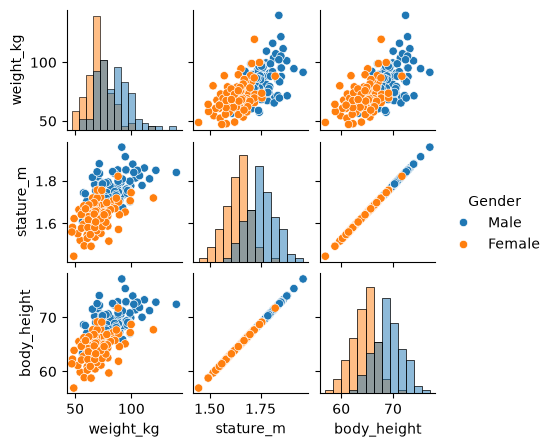

In [23]:
# Create a pairplot of the ansur_df_1 dataset
import matplotlib.pyplot as plt
import seaborn as sns
sns.pairplot(ansur_df_1, hue='Gender', diag_kind='hist', height=1.5)
plt.show()

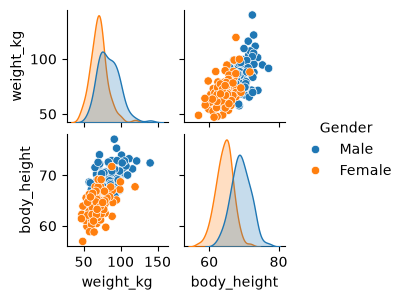

In [25]:
# Remove one of the redundant features
reduced_ansur_df_1 = ansur_df_1.drop(columns=['stature_m'])

sns.pairplot(reduced_ansur_df_1, hue='Gender', height=1.5)
plt.show()

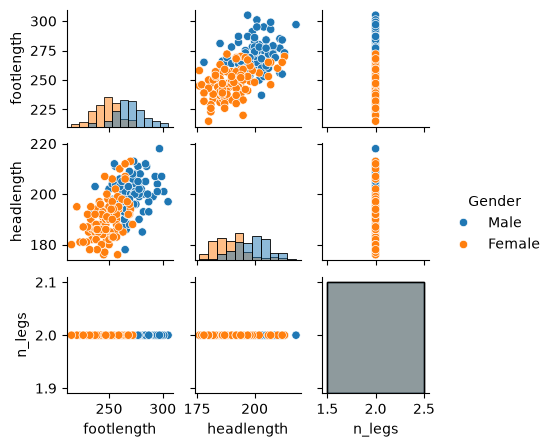

In [26]:
# Create a pairplot of the ansur_df_2 dataset
sns.pairplot(ansur_df_2, hue='Gender', diag_kind='hist', height=1.5)
plt.show()

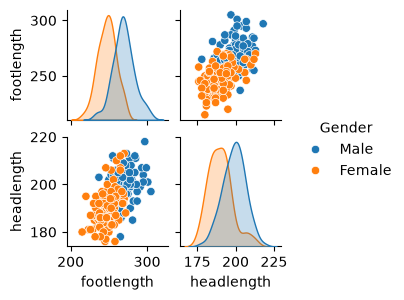

In [27]:
# Remove the redundant feature
reduced_ansur_df_2 = ansur_df_2.drop(columns=['n_legs'])

sns.pairplot(reduced_ansur_df_2, hue='Gender', height=1.5)
plt.show()

### t-SNE Visualization of High-Dimensional Data

In [29]:
# Load data
ansur_df = pd.read_csv('data/ansur_df.csv', index_col=0)

In [33]:
from sklearn.manifold import TSNE
non_numeric = ['Branch', 'Gender', 'Component']

ansur_df_numeric = ansur_df.drop(non_numeric, axis = 1)

# Create a t-SNE model
m = TSNE(learning_rate= 50)

tsne_features = m.fit_transform(ansur_df_numeric)
print(tsne_features.shape)

(6068, 2)


<Axes: xlabel='x', ylabel='y'>

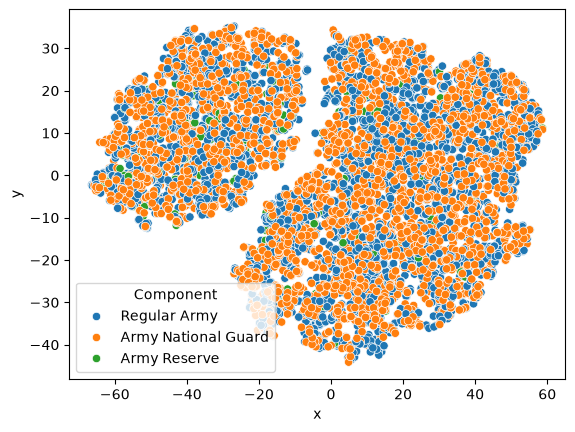

In [37]:
# Visualize t-SNE features
ansur_df['x'] = tsne_features[:,0]
ansur_df['y'] = tsne_features[:,1]

sns.scatterplot(x='x', y='y', hue='Component', data=ansur_df)

<Axes: xlabel='x', ylabel='y'>

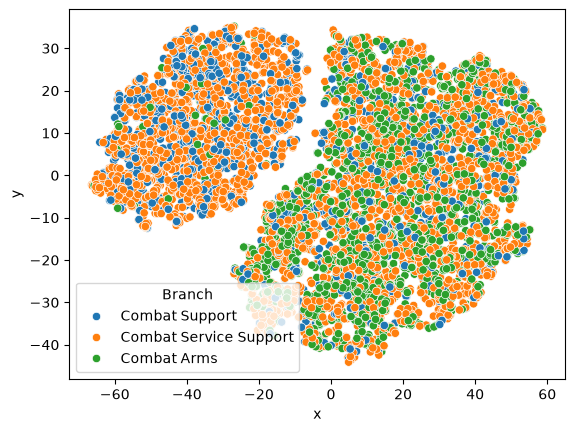

In [38]:
sns.scatterplot(x='x', y='y', hue='Branch', data=ansur_df)

<Axes: xlabel='x', ylabel='y'>

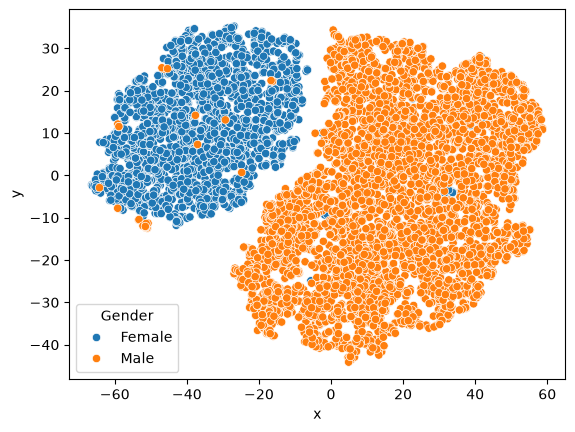

In [39]:
sns.scatterplot(x='x', y='y', hue='Gender', data=ansur_df)

## Feature Selection I - Selecting for Feature Information

### The Curse of Dimensionality

In [12]:
# Load ANSUR dataset
import pandas as pd
ansur_df = pd.read_csv('data/ansur_df_sample.csv', index_col=0)

In [13]:
# Split the dataset into features and target variable
from sklearn.model_selection import train_test_split

X = ansur_df.drop(columns=['Gender'])
y = ansur_df['Gender']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Print shapes
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(140, 92) (60, 92) (140,) (60,)


In [14]:
# Fitting and testing the model
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svc = SVC()

svc.fit(X_train, y_train)

accuracy_train = accuracy_score(y_train, svc.predict(X_train))
accuracy_test = accuracy_score(y_test, svc.predict(X_test))

print(f"Training accuracy: {accuracy_train:.2f}")
print(f"Testing accuracy: {accuracy_test:.2f}")

Training accuracy: 0.87
Testing accuracy: 0.85


In [15]:
# Reduce overfitting by reducing the number of features
X = ansur_df[['neckcircumferencebase']]
y = ansur_df['Gender']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

svc = SVC()
svc.fit(X_train, y_train)

accuracy_train = accuracy_score(y_train, svc.predict(X_train))
accuracy_test = accuracy_score(y_test, svc.predict(X_test))

print(f"Training accuracy: {accuracy_train:.2f}")
print(f"Testing accuracy: {accuracy_test:.2f}")

Training accuracy: 0.94
Testing accuracy: 0.98


In [16]:
# We see that neck circumference is single-handedly outperforming the model with all features. 
# This is a good example of how feature selection can help reduce overfitting and improve model performance.

### Features with small variance or missing values

In [30]:
head_df = pd.read_csv('data/head_df.csv', index_col=0)

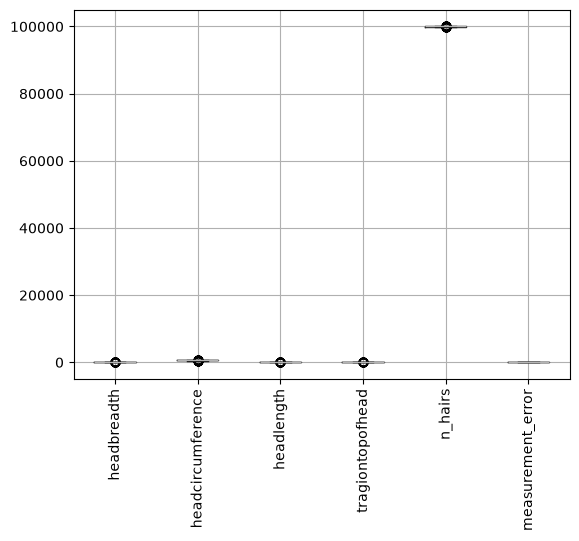

In [34]:
head_df.boxplot()
plt.xticks(rotation=90)
plt.show()

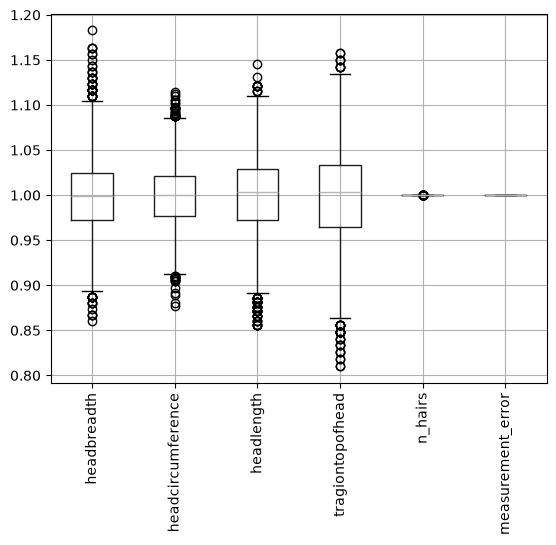

In [35]:
# Normalize data
import matplotlib.pyplot as plt
normalized_df = head_df / head_df.mean()

normalized_df.boxplot()
plt.xticks(rotation=90)
plt.show()

In [36]:
# Print variances of the normalized data
print(normalized_df.var())

headbreadth          1.678952e-03
headcircumference    1.029623e-03
headlength           1.867872e-03
tragiontopofhead     2.639840e-03
n_hairs              1.002552e-08
measurement_error    0.000000e+00
dtype: float64


In [37]:
# Features with low variance
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.001)
selector.fit(normalized_df)

mask = selector.get_support()

reduced_df = normalized_df.loc[:, mask]

print(f"Dimensionality reduced from {normalized_df.shape[1]} to {reduced_df.shape[1]} features.")

Dimensionality reduced from 6 to 4 features.


#### Missing Values

In [38]:
school_df = pd.read_csv('data/Public_Schools2.csv', index_col=0)
print(school_df.shape)

(131, 20)


In [39]:
# Missing value ratio
school_df.isna().sum() / len(school_df)

y             0.000000
objectid_1    0.000000
objectid      0.000000
bldg_id       0.000000
bldg_name     0.000000
address       0.000000
city          0.000000
zipcode       0.000000
csp_sch_id    0.000000
sch_id        0.000000
sch_name      0.000000
sch_label     0.000000
sch_type      0.000000
shared        0.877863
complex       0.984733
label         0.000000
tlt           0.000000
pl            0.000000
point_x       0.000000
point_y       0.000000
dtype: float64

In [40]:
mask = school_df.isna().sum() / len(school_df) < 0.5

reduced_school_df = school_df.loc[:, mask]

print(f"Dimensionality reduced from {school_df.shape[1]} to {reduced_school_df.shape[1]} features.")

Dimensionality reduced from 20 to 18 features.


### Pairwise Correlation

In [47]:
ansur_df = pd.read_csv('data/ansur_df.csv', index_col=0)

ansur_df = ansur_df[['elbowrestheight', 'wristcircumference', 'anklecircumference', 'buttockheight', 'crotchheight']]

In [49]:
# Print correlation matrix
print(ansur_df.corr())

                    elbowrestheight  wristcircumference  anklecircumference  \
elbowrestheight            1.000000            0.294753            0.301963   
wristcircumference         0.294753            1.000000            0.702178   
anklecircumference         0.301963            0.702178            1.000000   
buttockheight             -0.007013            0.576679            0.367548   
crotchheight              -0.026090            0.606582            0.386502   

                    buttockheight  crotchheight  
elbowrestheight         -0.007013     -0.026090  
wristcircumference       0.576679      0.606582  
anklecircumference       0.367548      0.386502  
buttockheight            1.000000      0.929411  
crotchheight             0.929411      1.000000  


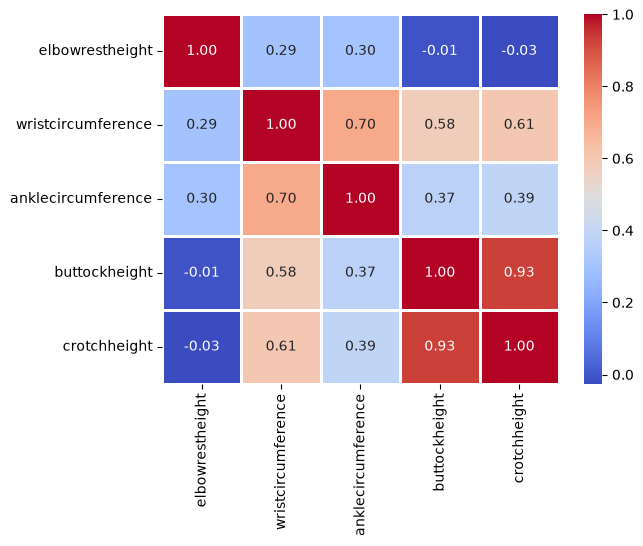

In [52]:
corr = ansur_df.corr()

# Draw a heatmap of the correlation matrix
import seaborn as sns
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=1, fmt='.2f')
plt.show()

In [53]:
# Generate a mask for the upper triangle
import numpy as np
mask = np.triu(np.ones_like(corr, dtype=bool))

print(mask)

[[ True  True  True  True  True]
 [False  True  True  True  True]
 [False False  True  True  True]
 [False False False  True  True]
 [False False False False  True]]


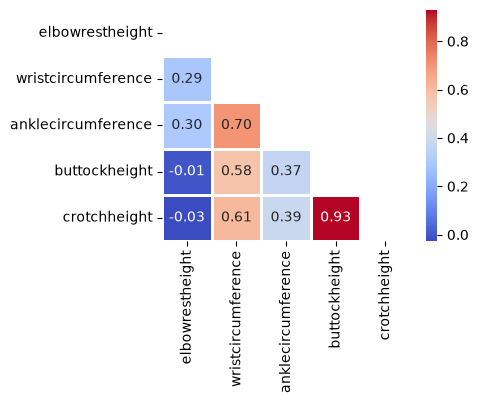

In [63]:
# Add mask to the heatmap
fig, ax = plt.subplots(figsize=(4, 3))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=1, fmt='.2f', mask=mask, ax=ax)
plt.show()

#### Filtering out highly correlated features

In [66]:
ansur_df = pd.read_csv('data/ansur_df.csv', index_col=0)

cat_columns = ['Branch', 'Gender', 'Component']
ansur_df = ansur_df.drop(cat_columns, axis=1)

In [67]:
corr_df = ansur_df.corr().abs()

mask = np.triu(np.ones_like(corr_df, dtype=bool))
tri_df = corr_df.mask(mask)

to_drop = [c for c in tri_df.columns if any(tri_df[c] > 0.95)]

reduced_ansur_df = ansur_df.drop(columns=to_drop)
print(f"Dimensionality reduced from {ansur_df.shape[1]} to {reduced_ansur_df.shape[1]} features.")

Dimensionality reduced from 91 to 73 features.


## Feature Selection II - Selecting for Model Accuracy

In [72]:
diabetes_df = pd.read_csv('data/diabetes.csv', index_col=0)

print(diabetes_df.head())

          glucose  diastolic  triceps  insulin   bmi  family  age      test
pregnant                                                                   
1              89         66       23       94  28.1   0.167   21  negative
0             137         40       35      168  43.1   2.288   33  positive
3              78         50       32       88  31.0   0.248   26  positive
2             197         70       45      543  30.5   0.158   53  positive
1             189         60       23      846  30.1   0.398   59  positive


In [96]:
X = diabetes_df.drop(columns=['test'])
y = diabetes_df['test']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)

In [97]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

lr = LogisticRegression()

lr.fit(X_train_std, y_train)

y_pred = lr.predict(X_test_std)


print(f"{accuracy_score(y_test, y_pred):.1%} accuracy on test set.")
print(dict(zip(X.columns, abs(lr.coef_[0]).round(2))))

76.5% accuracy on test set.
{'glucose': np.float64(1.19), 'diastolic': np.float64(0.03), 'triceps': np.float64(0.25), 'insulin': np.float64(0.05), 'bmi': np.float64(0.37), 'family': np.float64(0.41), 'age': np.float64(0.52)}


In [98]:
# Recursive Feature Elimination (RFE) with Logistic Regression
from sklearn.feature_selection import RFE
lr = LogisticRegression()
rfe = RFE(estimator=lr, n_features_to_select=4)

rfe.fit(X_train_std, y_train)

print(dict(zip(X.columns, rfe.ranking_)))

print(X.columns[rfe.support_])

acc = accuracy_score(y_test, rfe.predict(X_test_std))
print(f"{acc:.1%} accuracy on test set.")

{'glucose': np.int64(1), 'diastolic': np.int64(4), 'triceps': np.int64(2), 'insulin': np.int64(3), 'bmi': np.int64(1), 'family': np.int64(1), 'age': np.int64(1)}
Index(['glucose', 'bmi', 'family', 'age'], dtype='str')
77.6% accuracy on test set.


### Tree-based feature selection

In [100]:
diabetes = pd.read_csv('data/diabetes.csv', index_col=0)
X = diabetes.drop(columns=['test'])
y = diabetes['test']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [101]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=0)
rf.fit(X_train, y_train)

acc = accuracy_score(y_test, rf.predict(X_test))

# Print the importances per feature
print(dict(zip(X.columns, rf.feature_importances_.round(2))))

# Print accuracy
print(f"{acc:.1%} accuracy on test set.") 

{'glucose': np.float64(0.28), 'diastolic': np.float64(0.1), 'triceps': np.float64(0.1), 'insulin': np.float64(0.15), 'bmi': np.float64(0.13), 'family': np.float64(0.12), 'age': np.float64(0.14)}
78.6% accuracy on test set.


In [102]:
mask = rf.feature_importances_ > 0.15

reduced_X = X.loc[:, mask]
print(reduced_X.columns)

Index(['glucose'], dtype='str')


In [104]:
rfe = RFE(estimator=rf, n_features_to_select=2, verbose=1)
rfe.fit(X_train, y_train)

mask = rfe.support_

reduced_X = X.loc[:, mask]
print(reduced_X.columns)

Fitting estimator with 7 features.
Fitting estimator with 6 features.
Fitting estimator with 5 features.
Fitting estimator with 4 features.
Fitting estimator with 3 features.
Index(['glucose', 'insulin'], dtype='str')


In [106]:
rfe = RFE(estimator=rf, n_features_to_select=2, step = 2, verbose=1)
rfe.fit(X_train, y_train)

mask = rfe.support_

reduced_X = X.loc[:, mask]
print(reduced_X.columns)

Fitting estimator with 7 features.
Fitting estimator with 5 features.
Fitting estimator with 3 features.
Index(['glucose', 'bmi'], dtype='str')


### Regularized Linear Regression

In [1]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# Load the Ames Housing dataset
ames = fetch_openml(data_id=42165, as_frame=True)
df = ames.frame

# Take only numeric columns and fill missing values with 0
df_num = df.select_dtypes(include='number').fillna(0)

# Split the dataset into features and target variable
y = df_num['SalePrice']
X = df_num.drop(columns=['SalePrice'])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)
y_train_std = scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_std = scaler.transform(y_test.values.reshape(-1, 1)).ravel()

# 5. Baseline model with Lasso regression
lasso = Lasso(alpha=0.09, random_state=42)
lasso.fit(X_train_std, y_train_std)

# Evaluate the model
r_squared = lasso.score(X_test_std, y_test_std)
zero_coef = lasso.coef_ == 0
n_ignored = sum(zero_coef)

print(f"The model can predict {r_squared:.1%} of the variance in the test set.")
print(f"The model has ignored {n_ignored} out of {len(lasso.coef_)} features.")

The model can predict 77.8% of the variance in the test set.
The model has ignored 22 out of 37 features.


In [2]:
# Find the highest value for alpha that gives an value above 80% from the options: 1, 0.5, 0.1, and 0.01.
alphas = [1, 0.5, 0.1, 0.01, 0.001]

for alpha in alphas:
    lasso = Lasso(alpha=alpha, random_state=42)
    lasso.fit(X_train_std, y_train_std)
    r_squared = lasso.score(X_test_std, y_test_std)
    zero_coef = lasso.coef_ == 0
    n_ignored = sum(zero_coef)

    print(f"Alpha: {alpha}")
    print(f"R-squared: {r_squared:.1%}")
    print(f"Ignored features: {n_ignored} out of {len(lasso.coef_)}")
    print()

Alpha: 1
R-squared: -0.0%
Ignored features: 37 out of 37

Alpha: 0.5
R-squared: 37.9%
Ignored features: 35 out of 37

Alpha: 0.1
R-squared: 77.1%
Ignored features: 25 out of 37

Alpha: 0.01
R-squared: 82.5%
Ignored features: 13 out of 37

Alpha: 0.001
R-squared: 82.8%
Ignored features: 4 out of 37



In [3]:
# Use LassoCV to find the best alpha value
from sklearn.linear_model import LassoCV

lcv = LassoCV()
lcv.fit(X_train_std, y_train_std)
print(f"Best alpha value: {lcv.alpha_:.4f}")

Best alpha value: 0.0449


In [7]:
mask = lcv.coef_ != 0
sum(mask)

np.int64(15)

In [8]:
# Feature selection with Random Forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE

rfe_rf = RFE(estimator=RandomForestRegressor(random_state=42), n_features_to_select=15, step = 5, verbose=1)
rfe_rf.fit(X_train_std, y_train_std)
rf_mask = rfe_rf.support_

Fitting estimator with 37 features.
Fitting estimator with 32 features.
Fitting estimator with 27 features.
Fitting estimator with 22 features.
Fitting estimator with 17 features.


In [9]:
# Feature selection with Gradient Boosting
from sklearn.ensemble import GradientBoostingRegressor

rge_gb = RFE(estimator=GradientBoostingRegressor(random_state=42), n_features_to_select=15, step = 5, verbose=1)
rge_gb.fit(X_train_std, y_train_std)
gb_mask = rge_gb.support_

Fitting estimator with 37 features.
Fitting estimator with 32 features.
Fitting estimator with 27 features.
Fitting estimator with 22 features.
Fitting estimator with 17 features.


In [10]:
# Combining the feature selectors
import numpy as np

votes = np.sum([mask, rf_mask, gb_mask], axis=0)
print(votes)

[0 1 1 3 3 1 3 3 1 3 0 0 3 3 2 0 3 1 0 0 0 0 0 1 2 2 3 1 2 1 0 0 2 0 0 0 0]


In [11]:
mask = votes >= 2
mask

array([False, False, False,  True,  True, False,  True,  True, False,
        True, False, False,  True,  True,  True, False,  True, False,
       False, False, False, False, False, False,  True,  True,  True,
       False,  True, False, False, False,  True, False, False, False,
       False])

In [12]:
# PRACTICE

# Create LassoCV regressor
lcv = LassoCV()
lcv.fit(X_train_std, y_train_std)
print(f'Optimal alpha = {lcv.alpha_:.3f}')

# Calculate R squared on the test set
r_squared = lcv.score(X_test_std, y_test_std)
print(f'The model explains {r_squared:.1%} of the test set variance')

# Create a mask for coefficients not equal to zero
lcv_mask = lcv.coef_ != 0
print(f'{sum(lcv_mask)} features out of {len(lcv_mask)} selected')

Optimal alpha = 0.045
The model explains 80.3% of the test set variance
15 features out of 37 selected


In [13]:
# Ensemble models for extra votes

rfe_gb = RFE(estimator=GradientBoostingRegressor(random_state=42), n_features_to_select=15, step = 3, verbose=1)
rfe_gb.fit(X_train, y_train)

Fitting estimator with 37 features.
Fitting estimator with 34 features.
Fitting estimator with 31 features.
Fitting estimator with 28 features.
Fitting estimator with 25 features.
Fitting estimator with 22 features.
Fitting estimator with 19 features.
Fitting estimator with 16 features.


,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",GradientBoost...ndom_state=42)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",15
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",3
,"verbose verbose: int, default=0Controls verbosity of output.",1
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,GradientBoostingRegressor,GradientBoost...ndom_state=42)
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](37,)","['Id','MSSubClass','LotFrontage',...,'MiscVal','MoSold','YrSold']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(15)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,37
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](37,)","[6,5,6,...,9,7,8]"


In [15]:
# Calculate the R squared on the test set
r_squared = rfe_gb.score(X_test, y_test)
print(f'The model can explain {r_squared:.1%} of the variance in the test set')
gb_mask = rfe_gb.support_

The model can explain 89.9% of the variance in the test set


In [17]:
# Select 10 features with RFE on a RandomForestRegressor, drop 3 features on each step
rfe_rf = RFE(estimator=RandomForestRegressor(random_state=42), 
            n_features_to_select=15, step=3, verbose=1)
rfe_rf.fit(X_train, y_train)

# Calculate the R squared on the test set
r_squared = rfe_rf.score(X_test, y_test)
print(f'The model can explain {r_squared:.1%} of the variance in the test set')

# Assign the support array to rf_mask
rf_mask = rfe_rf.support_

Fitting estimator with 37 features.
Fitting estimator with 34 features.
Fitting estimator with 31 features.
Fitting estimator with 28 features.
Fitting estimator with 25 features.
Fitting estimator with 22 features.
Fitting estimator with 19 features.
Fitting estimator with 16 features.
The model can explain 89.9% of the variance in the test set


In [19]:
# Combine the masks from Lasso, Random Forest, and Gradient Boosting
votes = np.sum([lcv_mask, rf_mask, gb_mask], axis=0)

# Mask for features that received all three votes
meta_mask = votes >= 3
print(f'{sum(meta_mask)} features out of {len(meta_mask)} selected')

9 features out of 37 selected


In [20]:
X_reduced = X.loc[:, meta_mask]
print(X_reduced.columns)

Index(['LotArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF1',
       'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'GarageCars'],
      dtype='str')


In [21]:
# Plug the reduced dataset into a linear regression pipeline

from sklearn.linear_model import LinearRegression


lm = LinearRegression()

X_train, X_test, y_train, y_test = train_test_split(X_reduced, y, test_size=0.3, random_state=0)
lm.fit(scaler.fit_transform(X_train), y_train)
r_squared = lm.score(scaler.transform(X_test), y_test)
print(f'The model can explain {r_squared:.1%} of the variance in the test set using {len(lm.coef_)} features.')

The model can explain 71.3% of the variance in the test set using 9 features.


## Feature Extraction


In [27]:
# Load data
import pandas as pd

sales_df = pd.read_csv('data/grocery_sales.csv')
print(sales_df.head())

  storeID  product  quantity  revenue
0       A   Apples      1811   9300.6
1       A  Bananas      1003   3375.2
2       A  Oranges      1604   8528.5
3       B   Apples      1785   9181.0
4       B  Bananas       944   3680.2


### Manual Feature Extraction

In [33]:
# Calculate the price from the quantity sold and revenue, take 3 decimal places
sales_df['price'] = (sales_df['revenue'] / sales_df['quantity']).round(3)

# Drop the quantity and revenue features
reduced_df = sales_df.drop(['quantity', 'revenue'], axis=1)
print(reduced_df.head())

  storeID  product  price
0       A   Apples  5.136
1       A  Bananas  3.365
2       A  Oranges  5.317
3       B   Apples  5.143
4       B  Bananas  3.899


In [34]:
# Load data
height_df = pd.read_csv('data/height_df.csv', index_col=0)
print(height_df.head())

   weight_kg  height_1  height_2  height_3
0       81.5      1.78      1.80      1.80
1       72.6      1.70      1.70      1.69
2       92.9      1.74      1.75      1.73
3       79.4      1.66      1.68      1.67
4       94.6      1.91      1.93      1.90


In [35]:
# Calculate the mean height
height_df['height'] = height_df[['height_1', 'height_2', 'height_3']].mean(axis=1).round(3)

# Drop the 3 original height features
reduced_df = height_df.drop(['height_1', 'height_2', 'height_3'], axis=1)

print(reduced_df.head())

   weight_kg  height
0       81.5   1.793
1       72.6   1.697
2       92.9   1.740
3       79.4   1.670
4       94.6   1.913


### Principal Component Analysis (PCA)

In [2]:
# Load ANSUR dataset
import pandas as pd

ansur_df = pd.read_csv('data/ansur_pca.csv', index_col=0)

#### Calculating Principal Components

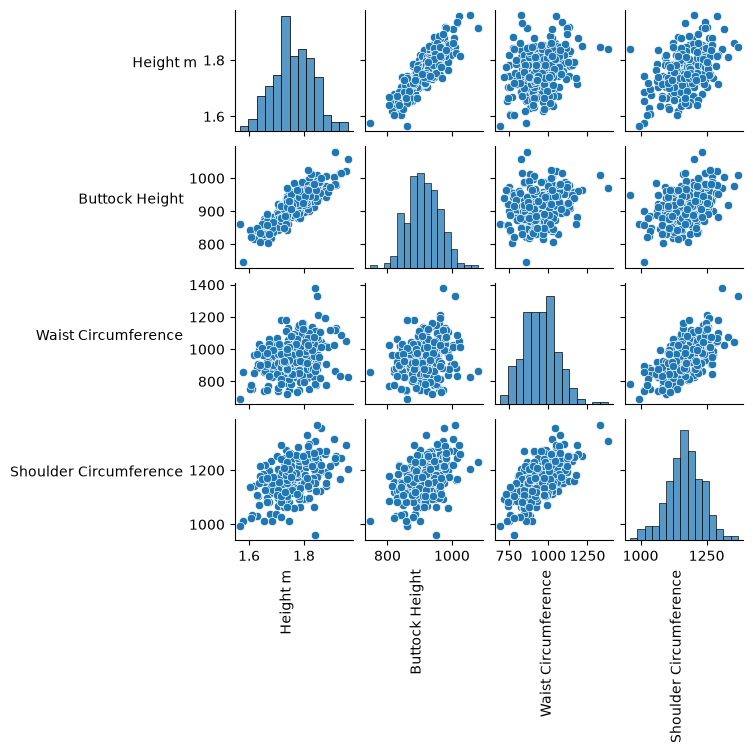

In [3]:
# Create a pairplot to inspect ansur_df
import matplotlib.pyplot as plt
import seaborn as sns

g = sns.pairplot(ansur_df, height=1.5)
[ax.set_ylabel(ax.get_ylabel(), rotation=0, ha='right') for ax in g.axes[:, 0]]
[ax.set_xlabel(ax.get_xlabel(), rotation=90, ha='right') for ax in g.axes[-1, :]]

plt.yticks(rotation=90)
plt.show()

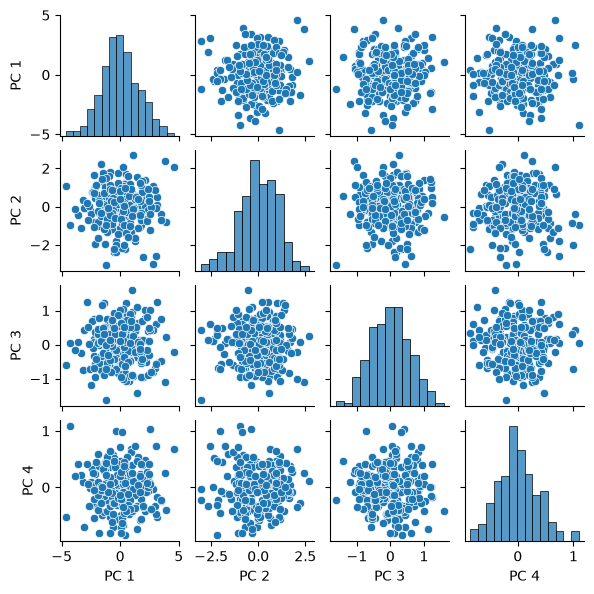

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Create the scaler and standardize the data
scaler = StandardScaler()
ansur_std = scaler.fit_transform(ansur_df)

# Create the PCA instance and fit and transform the data with pca
pca = PCA()
pc = pca.fit_transform(ansur_std)

# This changes the numpy array output back to a DataFrame
pc_df = pd.DataFrame(pc, columns=['PC 1', 'PC 2', 'PC 3', 'PC 4'])

# Create a pairplot of the principal component DataFrame
sns.pairplot(pc_df, height=1.5)
plt.show()

#### PCA on a larger dataset

In [6]:
ansur_df = pd.read_csv('data/ansur_df_13_dim.csv', index_col=0)
print(ansur_df.shape)

(250, 13)


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Scale the data
scaler = StandardScaler()
ansur_std = scaler.fit_transform(ansur_df)

# Apply PCA
pca = PCA()
pca.fit(ansur_std)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [8]:
# Inspect the explained variance ratio per component
print(pca.explained_variance_ratio_)

[0.61449404 0.19893965 0.06803095 0.03770499 0.03031502 0.0171759
 0.01072762 0.00656681 0.00634743 0.00436015 0.0026586  0.00202617
 0.00065268]


In [9]:
# Print the cumulative sum of the explained variance ratio
print(pca.explained_variance_ratio_.cumsum())

[0.61449404 0.81343368 0.88146463 0.91916962 0.94948464 0.96666054
 0.97738816 0.98395496 0.99030239 0.99466254 0.99732115 0.99934732
 1.        ]


In [11]:
# What's the lowest number of components that explain at least 90% of the variance in the dataset?
import numpy as np
print(np.argmax(pca.explained_variance_ratio_.cumsum() >= 0.9) + 1)

4


### PCA Applications

In [14]:
# Load Pokemon dataset
poke_df = pd.read_csv('data/pokemon.csv', index_col=0)

# Get only numeric columns
poke_df = poke_df.select_dtypes(include='number')

In [15]:
# Build the pipeline
from sklearn.pipeline import Pipeline


pipe = Pipeline([('scaler', StandardScaler()),
                ('reducer', PCA(n_components=2))])

# Fit it to the dataset and extract the component vectors
pipe.fit(poke_df)
vectors = pipe['reducer'].components_.round(2)

# Print feature effects
print('PC 1 effects = ' + str(dict(zip(poke_df.columns, vectors[0]))))
print('PC 2 effects = ' + str(dict(zip(poke_df.columns, vectors[1]))))

PC 1 effects = {'Total': np.float64(0.52), 'HP': np.float64(0.33), 'Attack': np.float64(0.38), 'Defense': np.float64(0.31), 'Sp. Atk': np.float64(0.39), 'Sp. Def': np.float64(0.38), 'Speed': np.float64(0.29), 'Generation': np.float64(0.04)}
PC 2 effects = {'Total': np.float64(0.01), 'HP': np.float64(-0.1), 'Attack': np.float64(-0.0), 'Defense': np.float64(-0.57), 'Sp. Atk': np.float64(0.28), 'Sp. Def': np.float64(-0.2), 'Speed': np.float64(0.64), 'Generation': np.float64(-0.36)}


In [17]:
# Inspect the PC 1 effects by sorting the dictionary by the absolute value of the effects
print(dict(zip(poke_df.columns, sorted(vectors[0], key=abs, reverse=True))))

{'Total': np.float64(0.52), 'HP': np.float64(0.39), 'Attack': np.float64(0.38), 'Defense': np.float64(0.38), 'Sp. Atk': np.float64(0.33), 'Sp. Def': np.float64(0.31), 'Speed': np.float64(0.29), 'Generation': np.float64(0.04)}


In [18]:
# Inspect the PC 2 effects by sorting the dictionary by the absolute value of the effects
print(dict(zip(poke_df.columns, sorted(vectors[1], key=abs, reverse=True))))

{'Total': np.float64(0.64), 'HP': np.float64(-0.57), 'Attack': np.float64(-0.36), 'Defense': np.float64(0.28), 'Sp. Atk': np.float64(-0.2), 'Sp. Def': np.float64(-0.1), 'Speed': np.float64(0.01), 'Generation': np.float64(-0.0)}


In [23]:
# Feature exploration with PCA
poke_df = pd.read_csv('data/pokemon.csv', index_col=0)

poke_num_df = poke_df.select_dtypes(include='number')
poke_cat_df = poke_df.select_dtypes(exclude='number')

In [24]:
# Build the pipeline
pipe = Pipeline([('scaler', StandardScaler()),
                ('reducer', PCA(n_components=2))])

# Fit the pipeline to poke_df and transform the data
pc = pipe.fit_transform(poke_num_df)

print(pc)

[[-1.88828896  0.51950497]
 [-0.49265201  0.56235125]
 [ 1.42997255  0.59541581]
 ...
 [ 2.86117152 -0.07428026]
 [ 4.12822037  0.32694247]
 [ 2.67954563 -1.05494327]]


In [25]:
# Add the 2 components to poke_cat_df
poke_cat_df['PC 1'] = pc[:, 0]
poke_cat_df['PC 2'] = pc[:, 1]

print(poke_cat_df.head())

                    Name Type 1  Type 2  Legendary      PC 1      PC 2
#                                                                     
1              Bulbasaur  Grass  Poison      False -1.888289  0.519505
2                Ivysaur  Grass  Poison      False -0.492652  0.562351
3               Venusaur  Grass  Poison      False  1.429973  0.595416
3  VenusaurMega Venusaur  Grass  Poison      False  3.009493 -0.081776
4             Charmander   Fire     NaN      False -2.094507  1.159673


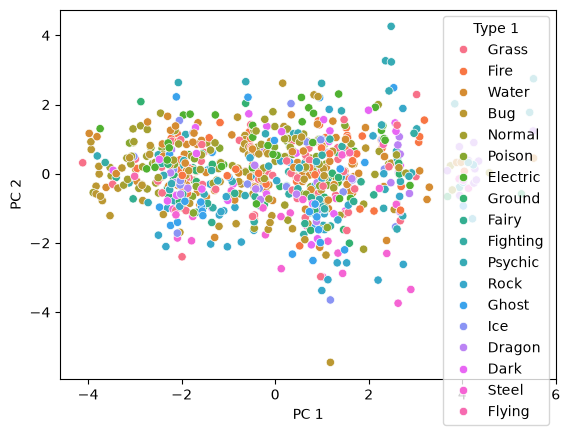

In [27]:
# Use the Type feature to color the PC 1 vs. PC 2 scatterplot
sns.scatterplot(data=poke_cat_df, 
                x='PC 1', y='PC 2', hue='Type 1')
plt.show()

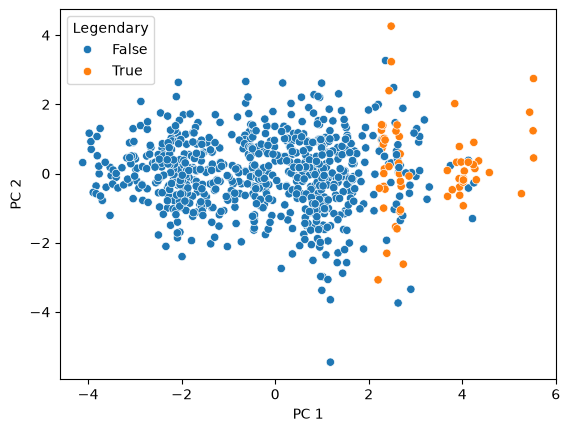

In [28]:
# Use the Legendary feature to color the PC 1 vs. PC 2 scatterplot
sns.scatterplot(data=poke_cat_df, 
                x='PC 1', y='PC 2', hue='Legendary')
plt.show()

In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(poke_num_df, poke_cat_df['Legendary'], test_size=0.3, random_state=0)

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

# Build the pipeline
pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('reducer', PCA(n_components=2)),
        ('classifier', RandomForestClassifier(random_state=0))])

# Fit the pipeline to the training data
pipe.fit(X_train, y_train)

# Prints the explained variance ratio
print(pipe['reducer'].explained_variance_ratio_)

[0.46725436 0.14656348]


In [33]:
# Score the accuracy on the test set
accuracy = pipe.score(X_test, y_test)

# Prints the model accuracy
print(f'{accuracy:.1%} test set accuracy')

95.8% test set accuracy


In [34]:
# Build the pipeline, change n_components to 3
pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('reducer', PCA(n_components=3)),
        ('classifier', RandomForestClassifier(random_state=0))])

# Fit the pipeline to the training data
pipe.fit(X_train, y_train)

# Score the accuracy on the test set
accuracy = pipe.score(X_test, y_test)

# Prints the explained variance ratio and accuracy
print(pipe['reducer'].explained_variance_ratio_)
print(f'{accuracy:.1%} test set accuracy')

[0.46725436 0.14656348 0.11916416]
92.5% test set accuracy


### Principal Component Selection

In [37]:
# Load ANSUR dataset
ansur_df = pd.read_csv('data/ansur_female.csv', index_col=0)

In [38]:
# Selecting the proportion of variance to keep
# Pipe a scaler to PCA selecting 80% of the variance
pipe = Pipeline([('scaler', StandardScaler()),
                ('reducer', PCA(n_components=0.8))])

# Fit the pipe to the data
pipe.fit(ansur_df)

print(f'{len(pipe["reducer"].components_)} components selected')

11 components selected


In [39]:
# Pipe a scaler to PCA selecting 90% of the variance
pipe = Pipeline([('scaler', StandardScaler()),
                ('reducer', PCA(n_components=0.9))])

# Fit the pipe to the data
pipe.fit(ansur_df)

print(f'{len(pipe["reducer"].components_)} components selected')

23 components selected


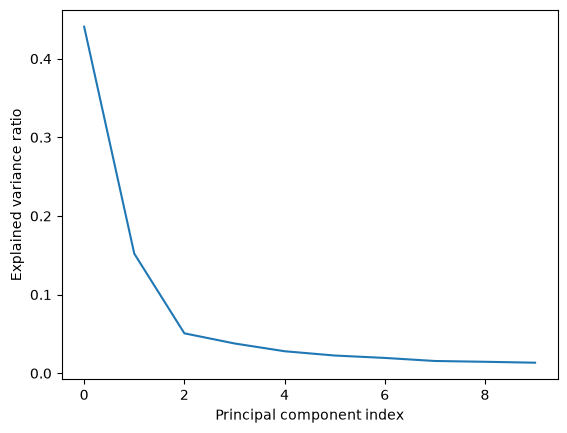

In [40]:
# Choosing the number of components to keep
pipe = Pipeline([('scaler', StandardScaler()),
                ('reducer', PCA(n_components=10))])

# Fit the pipe to the data
pipe.fit(ansur_df)

# Plot the explained variance ratio
plt.plot(pipe['reducer'].explained_variance_ratio_)

plt.xlabel('Principal component index')
plt.ylabel('Explained variance ratio')
plt.show()

In [41]:
# The elbow in the plot is at 3 components (the 3rd component has index 2)

#### PCA for image compression

In [59]:
from sklearn.datasets import fetch_openml
import numpy as np

mnist = fetch_openml('mnist_784', version=1, parser='auto')
X, y = mnist.data, mnist.target

X_test = X.iloc[:16].to_numpy()  

print(f"X_test shape: {X_test.shape}")

X_test shape: (16, 784)


In [ ]:
def plot_digits(data):
    fig, axes = plt.subplots(4, 4, figsize=(6, 6),
                            subplot_kw={'xticks':[], 'yticks':[]},
                            gridspec_kw=dict(hspace=0.05, wspace=0.05))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(28, 28),
                cmap='binary',
                clim=(0, 300))
    plt.show()

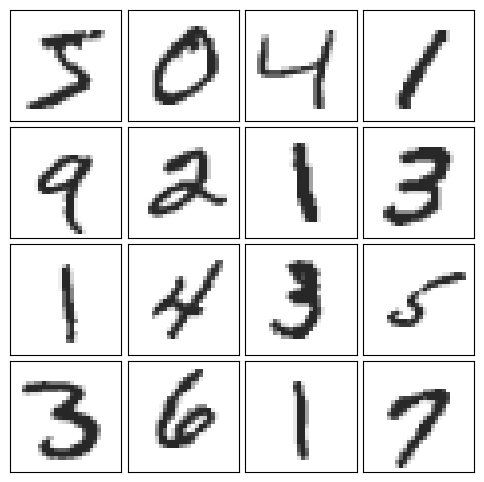

In [60]:
# Plot the MNIST sample data
plot_digits(X_test)

In [61]:
X_train = X.iloc[16:].to_numpy()

In [62]:
# A pipeline with a scaler and PCA model to select 78 components has been pre-loaded for you as pipe
pipe = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=78))])
pipe.fit(X_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('pca', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,784
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](784,)","[0.,0.,0.,...,0.,0.,0.]"


In [63]:
# Transform the input data to principal components
pc = pipe.transform(X_test)

# Prints the number of features per dataset
print(f"X_test has {X_test.shape[1]} features")
print(f"pc has {pc.shape[1]} features")

X_test has 784 features
pc has 78 features


In [64]:
# Inverse transform the components to original feature space
X_rebuilt = pipe.inverse_transform(pc)

# Prints the number of features
print(f"X_rebuilt has {X_rebuilt.shape[1]} features")

X_rebuilt has 784 features


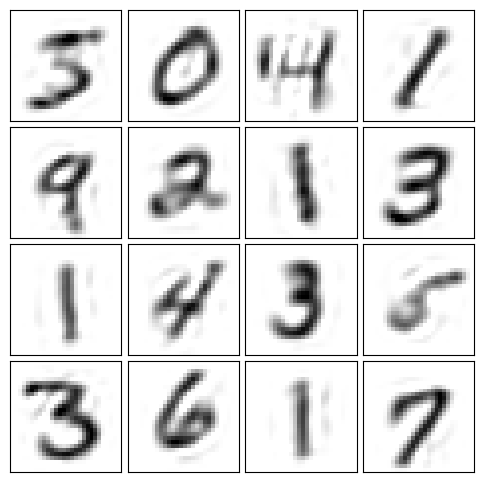

In [65]:
# Plot the reconstructed data
plot_digits(X_rebuilt)